# Figure S9: Total and Retained Trajectories per Cell

Trajectory counts per cell for UTag, UTag(ΔCys), SunTag, and ALFA-tag, before
and after removing trajectories with mean spot size >0.5 µm
(`SIZE_FILTER_MODE = "trajectory_mean"`). Spot size is used as an aggregate proxy.

Outputs are saved to:
- `figures/figure_spots_per_cell.png` and `.svg`
- `figures/figure_spots_per_cell_filtered.png` and `.svg`
- `raw_data/data_spots_per_cell.csv`
- `raw_data/data_spots_per_cell_filtered.csv`
- `raw_data/data_size_filter_audit.csv`
- `raw_data/data_pairwise_statistics.csv` (raw and Holm-adjusted Mann–Whitney U p-values; plot annotations use unadjusted p-values)


## 1. User Settings


In [1]:
from pathlib import Path

# ======================== START USER SETTINGS ========================

# Input and output locations
INPUT_ROOT = Path("/Volumes/Luis_DRIVE/UTag_paper_data/ACF")
FIGURES_FOLDER_NAME = "figures"
DATA_FOLDER_NAME = "raw_data"

# Conditions: folder, displayed label, CSV label, and color
CONDITIONS = {
    "utag": {
        "folder": "UTag_ACF",
        "label": "UTag",
        "export_label": "UTag",
        "color": "#0173B2",
    },
    "utag_c_free": {
        "folder": "UTag_CF_ACF",
        "label": r"UTag($\Delta$Cys)",
        "export_label": "UTag_DeltaCys",
        "color": "#DE8F05",
    },
    "suntag": {
        "folder": "SunTag_ACF",
        "label": "SunTag",
        "export_label": "SunTag",
        "color": "#029E73",
    },
    "alfatag": {
        "folder": "AlfaTag_ACF",
        "label": "ALFA-tag",
        "export_label": "ALFA_tag",
        "color": "#CC78BC",
    },
}

# Analysis settings
CHANNEL_INDEX = 0
SELECTED_FRAME = None
USE_METADATA_PIXEL_SIZE = False
FIXED_PIXEL_XY_UM = 0.12989318982387477
MINIMUM_SNR = 0.0
SPOT_SIZE_THRESHOLD_UM = 0.5
# Whole-trajectory mean filter: removes entire trajectories with mean size > 0.5 µm
SIZE_FILTER_MODE = "trajectory_mean"

# Box-and-whisker figure definitions:
# 1. Total trajectories per cell (raw)
# 2. Retained trajectories per cell (filtered: trajectory mean size <= 0.5 µm)
WHISKER_FIGURES = {
    "spots_per_cell": {
        "figure_name": "figure_spots_per_cell",
        "data_name": "data_spots_per_cell.csv",
        "y_label": "Trajectories per cell",
        "y_limits": None,
    },
    "spots_per_cell_filtered": {
        "figure_name": "figure_spots_per_cell_filtered",
        "data_name": "data_spots_per_cell_filtered.csv",
        "y_label": "Retained trajectories per cell",
        "y_limits": None,
    },
}

PAIRWISE_STATISTICS_DATA_NAME = "data_pairwise_statistics.csv"
SIZE_FILTER_AUDIT_DATA_NAME = "data_size_filter_audit.csv"

# Shared plot appearance
FONT_FAMILY = "Arial"
WHISKER_STYLE = {
    "figsize": (6.5, 4.5),
    "tick_size": 18,
    "show_stats": True,
    "save_formats": ("png", "svg"),
    "save_dpi": 600,
}
SHOW_SUMMARY_TABLES = True

# ========================= END USER SETTINGS =========================


## 2. Setup and Load Tracking Data


In [2]:
import sys
import warnings
import matplotlib.pyplot as plt
import seaborn as sns
from IPython.display import display

def find_project_dir(start_path):
    """Return the nearest parent directory containing the Git repository."""
    start_path = Path(start_path).resolve()
    for candidate in (start_path, *start_path.parents):
        if (candidate / ".git").exists():
            return candidate
    raise FileNotFoundError(f"Could not locate the project root from {start_path}.")

PROJECT_DIR = find_project_dir(Path.cwd())
NOTEBOOK_DIR = PROJECT_DIR / "notebooks" / "Figure_7_and_S9_spot_distributions"
FIGURES_DIR = NOTEBOOK_DIR / FIGURES_FOLDER_NAME
RAW_DATA_DIR = NOTEBOOK_DIR / DATA_FOLDER_NAME
FIGURES_DIR.mkdir(parents=True, exist_ok=True)
RAW_DATA_DIR.mkdir(parents=True, exist_ok=True)

if str(NOTEBOOK_DIR) not in sys.path:
    sys.path.insert(0, str(NOTEBOOK_DIR))

from processing_spot_size import (
    load_tracking_records,
    build_audit_dataframe,
    build_size_filter_audit,
    run_whisker_analyses,
    save_pairwise_statistics,
)

CONDITION_KEYS = tuple(CONDITIONS)
DATASET_FOLDERS = {k: v["folder"] for k, v in CONDITIONS.items()}
CONDITION_LABELS = {k: v["label"] for k, v in CONDITIONS.items()}
CONDITION_EXPORT_LABELS = {k: v["export_label"] for k, v in CONDITIONS.items()}
CONDITION_COLORS = {k: v["color"] for k, v in CONDITIONS.items()}

%matplotlib inline
warnings.filterwarnings("ignore", category=FutureWarning)
sns.set_style("ticks")
plt.rcParams.update({
    "font.family": FONT_FAMILY,
    "text.color": "black",
    "axes.labelcolor": "black",
    "axes.edgecolor": "black",
    "xtick.color": "black",
    "ytick.color": "black",
    "axes.linewidth": 2.0,
    "axes.labelsize": 22,
    "xtick.labelsize": 18,
    "ytick.labelsize": 18,
    "legend.fontsize": 15,
    "figure.facecolor": "white",
    "axes.facecolor": "white",
    "savefig.facecolor": "white",
})

print(f"Input root: {INPUT_ROOT}")
print(f"Figures:    {FIGURES_DIR}")
print(f"Raw data:   {RAW_DATA_DIR}")

TRACKING_RECORDS = load_tracking_records(
    INPUT_ROOT,
    DATASET_FOLDERS,
    use_metadata_pixel_size=USE_METADATA_PIXEL_SIZE,
    fixed_pixel_xy_um=FIXED_PIXEL_XY_UM,
)

# Display audit summary
audit_df = build_audit_dataframe(TRACKING_RECORDS, CONDITION_LABELS)
display(audit_df)

# Display size filter retention breakdown
filter_audit_df = build_size_filter_audit(
    TRACKING_RECORDS,
    CONDITION_KEYS,
    CONDITION_LABELS,
    threshold_um=SPOT_SIZE_THRESHOLD_UM,
    channel_index=CHANNEL_INDEX,
    min_snr=MINIMUM_SNR,
    selected_frame=SELECTED_FRAME,
    size_filter_mode=SIZE_FILTER_MODE,
)
filter_audit_path = RAW_DATA_DIR / SIZE_FILTER_AUDIT_DATA_NAME
filter_audit_df.to_csv(filter_audit_path, index=False)
print(f"Saved size filter audit: {filter_audit_path}")

# Summary table of trajectory retention per condition
summary_retention = filter_audit_df.groupby("condition")[[
    "trajectories_before_filter", "trajectories_retained", "trajectories_losing_all_detections"
]].sum().reset_index()
summary_retention["retention_pct"] = (summary_retention["trajectories_retained"] / summary_retention["trajectories_before_filter"]) * 100.0
print("=== Trajectory Retention Summary Across Conditions ===")
display(summary_retention)


Input root: /Volumes/LaCie/UTag_paper_data/ACF
Figures:    /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/figures
Raw data:   /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/raw_data


,condition,cells/files,dataframe rows,unique particles,pixel sizes (um/px)
0,UTag,19,139658,1257,[0.129893189824]
1,UTag($\Delta$Cys),14,94722,1011,[0.129893189824]
2,SunTag,16,65280,682,[0.129893189824]
3,ALFA-tag,11,76489,652,[0.129893189824]


Saved size filter audit: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/raw_data/data_size_filter_audit.csv
=== Trajectory Retention Summary Across Conditions ===


,condition,trajectories_before_filter,trajectories_retained,trajectories_losing_all_detections,retention_pct
0,ALFA-tag,652,648,4,99.386503
1,SunTag,682,605,77,88.709677
2,UTag,1257,1246,11,99.124901
3,UTag($\Delta$Cys),1011,944,67,93.372898


## 3. Total and Retained Trajectories per Cell (Box-and-Whisker Plots)


Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/figures/figure_spots_per_cell.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/figures/figure_spots_per_cell.svg


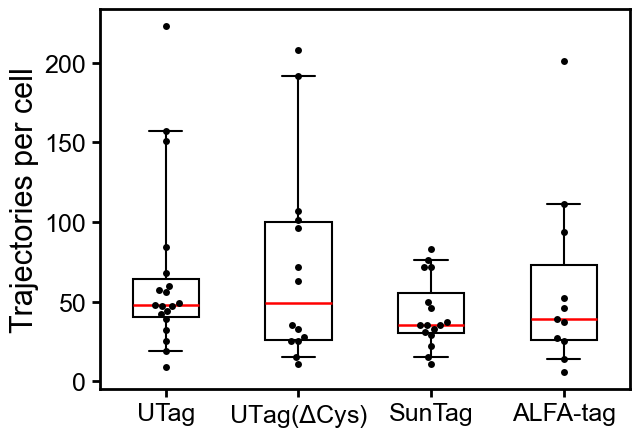

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/raw_data/data_spots_per_cell.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/figures/figure_spots_per_cell_filtered.png | /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/figures/figure_spots_per_cell_filtered.svg


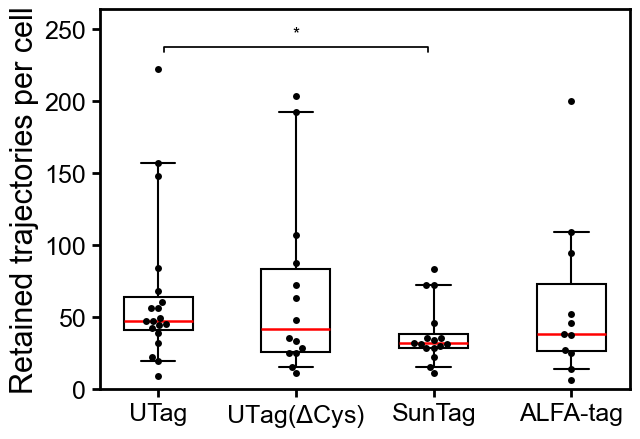

Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/raw_data/data_spots_per_cell_filtered.csv
Saved: /Users/nzlab-la/Desktop/utag_paper/notebooks/Figure_7_and_S9_spot_distributions/raw_data/data_pairwise_statistics.csv

=== Summary Statistics: Trajectories per cell ===


,Condition,count,mean,std,median
0,UTag,19,66.157895,53.809606,48.0
1,UTag($\Delta$Cys),14,72.214286,63.143522,49.0
2,SunTag,16,42.625000,22.126530,35.0
3,ALFA-tag,11,59.272727,56.752253,39.0



=== Summary Statistics: Retained trajectories per cell ===


,Condition,count,mean,std,median
0,UTag,19,65.578947,53.589298,47.0
1,UTag($\Delta$Cys),14,67.428571,61.762217,41.5
2,SunTag,16,37.812500,20.569293,31.5
3,ALFA-tag,11,58.909091,56.358592,38.0



=== Combined Pairwise Statistics (Mann-Whitney U) ===


,plot,condition_1,condition_2,test,alternative,p_value_raw,significance_raw,p_value_holm,significance_holm,annotation_displayed,annotation_basis
0,figure_spots_per_cell,UTag,UTag_DeltaCys,Mann-Whitney U,two-sided,0.956408,ns,1.000000,ns,False,raw p-value
1,figure_spots_per_cell,UTag,SunTag,Mann-Whitney U,two-sided,0.149575,ns,0.897450,ns,False,raw p-value
2,figure_spots_per_cell,UTag,ALFA_tag,Mann-Whitney U,two-sided,0.365960,ns,1.000000,ns,False,raw p-value
3,figure_spots_per_cell,UTag_DeltaCys,SunTag,Mann-Whitney U,two-sided,0.491899,ns,1.000000,ns,False,raw p-value
4,figure_spots_per_cell,UTag_DeltaCys,ALFA_tag,Mann-Whitney U,two-sided,0.721754,ns,1.000000,ns,False,raw p-value
5,figure_spots_per_cell,SunTag,ALFA_tag,Mann-Whitney U,two-sided,0.674564,ns,1.000000,ns,False,raw p-value
6,figure_spots_per_cell_filtered,UTag,UTag_DeltaCys,Mann-Whitney U,two-sided,0.812790,ns,1.000000,ns,False,raw p-value
7,figure_spots_per_cell_filtered,UTag,SunTag,Mann-Whitney U,two-sided,0.035389,*,0.212337,ns,True,raw p-value
8,figure_spots_per_cell_filtered,UTag,ALFA_tag,Mann-Whitney U,two-sided,0.389282,ns,1.000000,ns,False,raw p-value
9,figure_spots_per_cell_filtered,UTag_DeltaCys,SunTag,Mann-Whitney U,two-sided,0.327752,ns,1.000000,ns,False,raw p-value


In [3]:
WHISKER_RESULTS, PAIRWISE_STATISTICS = run_whisker_analyses(
    tracking_records=TRACKING_RECORDS,
    condition_keys=CONDITION_KEYS,
    display_labels=CONDITION_LABELS,
    export_labels=CONDITION_EXPORT_LABELS,
    figures=WHISKER_FIGURES,
    figures_dir=FIGURES_DIR,
    raw_data_dir=RAW_DATA_DIR,
    channel_index=CHANNEL_INDEX,
    selected_frame=SELECTED_FRAME,
    threshold_um=SPOT_SIZE_THRESHOLD_UM,
    minimum_snr=MINIMUM_SNR,
    style=WHISKER_STYLE,
    size_filter_mode=SIZE_FILTER_MODE,
)

# Combine and save pairwise statistical tests for both figures (Mann-Whitney U with Holm adjustment)
stats_path = RAW_DATA_DIR / PAIRWISE_STATISTICS_DATA_NAME
pairwise_statistics = save_pairwise_statistics(PAIRWISE_STATISTICS, stats_path)

if SHOW_SUMMARY_TABLES:
    for key, fig_cfg in WHISKER_FIGURES.items():
        print(f"\n=== Summary Statistics: {fig_cfg['y_label']} ===")
        display(WHISKER_RESULTS[key]["summary"])
    print("\n=== Combined Pairwise Statistics (Mann-Whitney U) ===")
    display(pairwise_statistics)
